# Application of course models

GroupXX ? Data Mining I ? 2026/2027

Complete group names and student numbers before submission.

This notebook covers the supplied course list through an RFM applicability check,
K-means, Ward hierarchical clustering, DBSCAN, and Self-Organizing Maps (SOM).
It reads `../outputs/student_data_preprocessed.csv`. Run preprocessing first, then
run this notebook from the `notebooks/` directory.

## Exploratory settings and inherited assumptions

The input preprocessing includes draft choices documented in its notebook.
All students retain their source row identifiers. Identifiers are excluded from
model features. G3 represents academic performance, while G1 and G2 are used for
profiling. Ordinal education is mapped to 0-4, ratings retain their 1-5 values,
numerical fields use MinMax scaling, and nominal fields use full one-hot encoding.
Unknown remains a baseline category for missing Yes/No responses.

Full one-hot encoding gives equal within-feature distance to distinct categories.
A nominal feature can contribute squared distance 2, compared with at most 1 for
a scaled numerical feature. Feature weighting therefore requires later review.
Candidate k values 2-5, DBSCAN parameter grids, and SOM grid choices are exploratory.
Automatically selected settings support investigation and require review alongside
cluster sizes, profiles, and sensitivity results.

## Course evidence and API sources

Practical 4 `K_Means.ipynb` provides scaling (cell 17), elbow comparisons
(26-28), Ward linkage and dendrogram (34-36), and K-means (40-47).
Cell references are zero-based. RFM, DBSCAN and SOM are included from the user's
course topic list. Their implementations extend the supplied notebook examples.
Silhouette and adjusted Rand index also extend those examples.

Silhouette contrasts within-cluster with between-cluster dissimilarity.
ARI compares assignments for the same students and is 1 for equivalent partitions.
Metrics depend on the population and representation. DBSCAN's noise-excluded
silhouette uses a different population and should be considered with coverage.

Primary API references are the
[scikit-learn clustering guide](https://scikit-learn.org/stable/modules/clustering.html),
[DBSCAN documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html),
[ silhouette reference](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html),
[SciPy fcluster documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.fcluster.html),
and [MiniSom implementation and examples](https://github.com/JustGlowing/minisom).

## Environment and parameters

Record package versions and reproducible candidate settings. SOM training requires the minisom package in the selected kernel.

In [4]:
import sys
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from minisom import MiniSom

SEED = 42
candidate_ks = range(2, 6)
print('Python', sys.version.split()[0])
for package in ['pandas', 'numpy', 'scikit-learn', 'scipy', 'matplotlib', 'seaborn', 'minisom']:
    print(package, version(package))

Python 3.14.10
pandas 3.1.1
numpy 2.5.4
scikit-learn 1.9.1
scipy 1.18.1
matplotlib 3.11.2
seaborn 0.13.2
minisom 2.3.6


## Load prepared and recorded values

Preserve literal None education values and load the source row identifiers.
The raw observations supply modes for the later sensitivity experiment.

In [5]:
student_data = pd.read_csv(
    '../outputs/student_data_preprocessed.csv',
    index_col='student_row_id', keep_default_na=False, na_values=['']
)
recorded_data = pd.read_csv(
    '../data/raw/student_data.csv', index_col=0,
    keep_default_na=False, na_values=['']
)
assert student_data.index.equals(recorded_data.index)
assert student_data.isna().sum().sum() == 0
assert student_data.index.is_unique
print('Prepared dataset', student_data.shape)

Prepared dataset (649, 32)


## RFM analysis and applicability

RFM describes each entity using recency (time since the latest event), frequency
(number of events in a defined window), and monetary value (spend in that window).
A reproducible application specifies the event, observation window, reference date,
entity identifier, and value measure before creating scores or segments.

The student CSV contains static student attributes and period grades. It provides
no dated transaction or engagement-event log and no monetary-value field. The
schema check below documents the data required for an appropriate RFM application.
An educational adaptation would need dated activities and a separately justified
value definition. Grade, age, and absence counts cannot supply those inputs alone.

In [6]:
rfm_requirements = pd.DataFrame({
    'Required input': ['Entity identifier', 'Dated event history', 'Defined observation window', 'Monetary or justified value measure'],
    'Available in this dataset': ['Source row identifier only', 'Absent', 'Absent', 'Absent'],
    'Role': ['Group events by entity', 'Calculate recency and event frequency', 'Make frequency and value comparable', 'Calculate the value component']
})
display(rfm_requirements)
print('RFM scoring requires additional event-level data and a justified value definition.')

,Required input,Available in this dataset,Role
0,Entity identifier,Source row identifier only,Group events by entity
1,Dated event history,Absent,Calculate recency and event frequency
2,Defined observation window,Absent,Make frequency and value comparable
3,Monetary or justified value measure,Absent,Calculate the value component


RFM scoring requires additional event-level data and a justified value definition.


## Select and represent features

The numerical set includes age, habits, recorded counts, ordered education and
ratings, and final grade. Nominal fields represent context and support.
Inspect these lists before deciding how similarity should be defined.

In [7]:
rating_columns = ['famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health']
yes_no_columns = [
    'schoolsup', 'famsup', 'paid', 'activities',
    'nursery', 'higher', 'internet', 'romantic'
]
education_columns = ['Medu', 'Fedu']
numeric_columns = [
    'age', 'traveltime', 'studytime', 'failures', 'absences',
    'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health',
    'Medu', 'Fedu', 'G3'
]
categorical_columns = [
    'school', 'sex', 'address', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian'
] + yes_no_columns
education_mapping = {
    'None': 0, 'Primary Education': 1, 'Middle School Education': 2,
    'Secondary Education': 3, 'Higher Education': 4
}
model_data = student_data[numeric_columns + categorical_columns].copy()
for column in education_columns:
    assert model_data[column].isin(education_mapping).all()
    model_data[column] = model_data[column].map(education_mapping)
assert set(model_data.columns) == set(student_data.columns) - {'G1', 'G2'}
display(pd.DataFrame({
    'Role': ['Numerical / ordered', 'Nominal'],
    'Features': [len(numeric_columns), len(categorical_columns)]
}))

,Role,Features
0,Numerical / ordered,14
1,Nominal,16


## Prepare model matrices

Scale numerical values and retain original row labels when reconstructing the
DataFrame. K-means, Ward, DBSCAN, and SOM receive the same encoded representation.
This aligns their definition of student similarity for the baseline experiments.


In [8]:
scaler = MinMaxScaler()
scaled_numeric = pd.DataFrame(
    scaler.fit_transform(model_data[numeric_columns]),
    columns=numeric_columns, index=model_data.index
)
categorical_indicators = pd.get_dummies(
    model_data[categorical_columns], drop_first=False, dtype=float
)
encoded_data = pd.concat([scaled_numeric, categorical_indicators], axis=1)
assert encoded_data.index.equals(student_data.index)
assert np.isfinite(encoded_data.to_numpy()).all()
print('K-means and Ward matrix', encoded_data.shape)


K-means and Ward matrix (649, 70)


## K-means candidate solutions

Fit each candidate k with repeated initializations. Inertia describes within-cluster
squared Euclidean dispersion. Silhouette and the smallest cluster size complement
that objective. The tentative k maximizes silhouette within these candidates.

In [9]:
kmeans_models = {}
kmeans_results = []
for k in candidate_ks:
    model = KMeans(n_clusters=k, random_state=SEED, n_init=20)
    model.fit(encoded_data)
    labels = model.labels_
    kmeans_models[k] = model
    kmeans_results.append({
        'k': k, 'Inertia': model.inertia_,
        'Silhouette': silhouette_score(encoded_data, labels),
        'Smallest cluster': pd.Series(labels).value_counts().min()
    })
kmeans_summary = pd.DataFrame(kmeans_results).set_index('k')
display(kmeans_summary.round(3))
best_kmeans_k = int(kmeans_summary['Silhouette'].idxmax())
kmeans_model = kmeans_models[best_kmeans_k]

,Inertia,Silhouette,Smallest cluster
k,,,
2,4748.502,0.083,247
3,4518.449,0.062,206
4,4389.384,0.051,151
5,4269.564,0.054,109


### K-means objective and separation

Inspect the inertia curve alongside silhouette before interpreting the tentative
selection. The elbow is a visual aid and requires context.

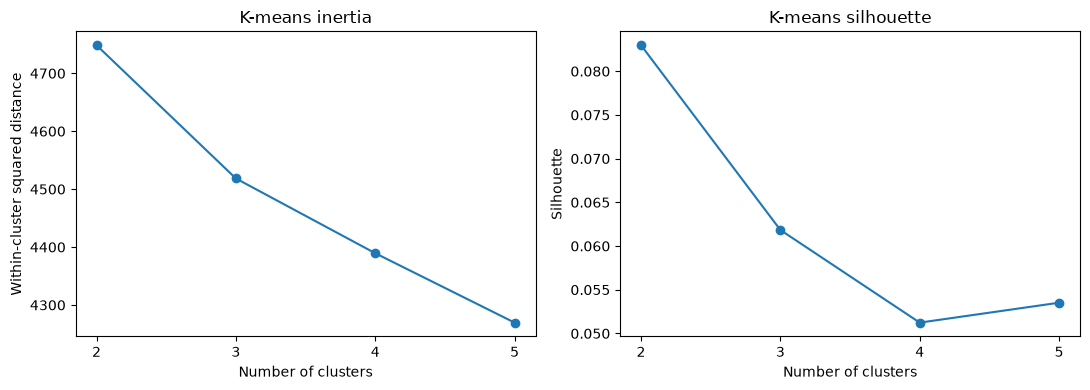

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(kmeans_summary.index, kmeans_summary['Inertia'], marker='o')
axes[0].set_title('K-means inertia')
axes[0].set_ylabel('Within-cluster squared distance')
axes[1].plot(kmeans_summary.index, kmeans_summary['Silhouette'], marker='o')
axes[1].set_title('K-means silhouette')
axes[1].set_ylabel('Silhouette')
for axis in axes:
    axis.set_xlabel('Number of clusters')
    axis.set_xticks(list(candidate_ks))
plt.tight_layout()
plt.show()

## Ward hierarchical clustering

Construct a hierarchy using the same Euclidean representation as K-means.
The truncated dendrogram summarizes the final merges. Cuts use `maxclust`,
which requests at most k groups. The observed number is checked for each cut.

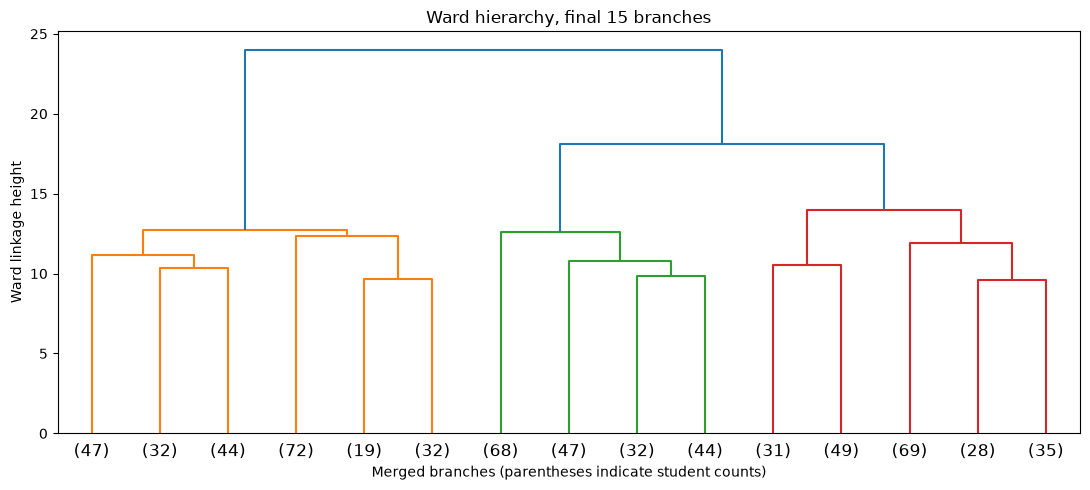

,Silhouette,Smallest cluster
k,,
2,0.064,246
3,0.033,191
4,0.027,80
5,0.029,80


In [11]:
hierarchical_tree = linkage(encoded_data, method='ward')
plt.figure(figsize=(11, 5))
dendrogram(hierarchical_tree, truncate_mode='lastp', p=15)
plt.title('Ward hierarchy, final 15 branches')
plt.xlabel('Merged branches (parentheses indicate student counts)')
plt.ylabel('Ward linkage height')
plt.tight_layout()
plt.show()

ward_labels = {}
ward_results = []
for k in candidate_ks:
    labels = fcluster(hierarchical_tree, t=k, criterion='maxclust') - 1
    observed_k = len(np.unique(labels))
    assert observed_k == k
    ward_labels[k] = labels
    ward_results.append({
        'k': k, 'Silhouette': silhouette_score(encoded_data, labels),
        'Smallest cluster': pd.Series(labels).value_counts().min()
    })
ward_summary = pd.DataFrame(ward_results).set_index('k')
display(ward_summary.round(3))
best_ward_k = int(ward_summary['Silhouette'].idxmax())

## DBSCAN and neighborhood distances

DBSCAN forms dense groups using a neighborhood radius eps and min_samples,
which includes the point itself. Sparse observations receive label -1.
The sorted fifth-neighbor distances provide a visual parameter aid. Explicit
self-neighbors are included so the distance index matches min_samples = 5.

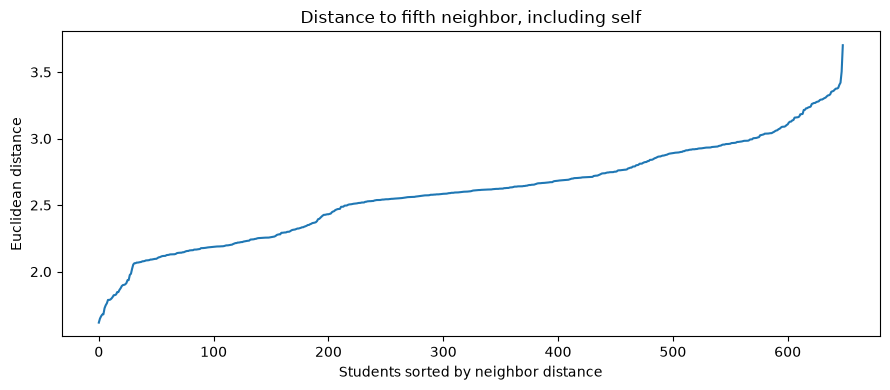

In [12]:
baseline_neighbors = NearestNeighbors(n_neighbors=5)
baseline_neighbors.fit(encoded_data)
neighbor_distances, neighbor_indices = baseline_neighbors.kneighbors(encoded_data)
plt.figure(figsize=(9, 4))
plt.plot(np.sort(neighbor_distances[:, -1]))
plt.title('Distance to fifth neighbor, including self')
plt.xlabel('Students sorted by neighbor distance')
plt.ylabel('Euclidean distance')
plt.tight_layout()
plt.show()

### DBSCAN parameter comparison

For min_samples values 5, 10 and 20, candidate radii use the 10th, 25th, 50th,
75th and 90th percentiles of the corresponding neighbor distances. These are
exploratory settings. Inspect cluster count, noise percentage and silhouette
among assigned students together. Silhouette is calculated only for at least
two non-noise groups and fewer groups than assigned students.

For a tentative profile, prefer a multi-group candidate with the greatest
assigned coverage, using silhouette to break ties. If all candidates produce
at most one group, display the highest-coverage candidate and report that
this grid supplied insufficient evidence for multiple dense groups.

In [13]:
dbscan_results = []
dbscan_candidates = []
for min_samples in [5, 10, 20]:
    neighbors = NearestNeighbors(n_neighbors=min_samples).fit(encoded_data)
    distances, indices = neighbors.kneighbors(encoded_data)
    eps_candidates = np.unique(np.quantile(distances[:, -1], [0.10, 0.25, 0.50, 0.75, 0.90]))
    for eps in eps_candidates:
        model = DBSCAN(eps=float(eps), min_samples=min_samples)
        model.fit(encoded_data)
        labels = model.labels_
        assigned = labels != -1
        clusters = len(np.unique(labels[assigned]))
        score = np.nan
        if 2 <= clusters < assigned.sum():
            score = silhouette_score(encoded_data.loc[assigned], labels[assigned])
        dbscan_candidates.append(model)
        dbscan_results.append({
            'Candidate': len(dbscan_candidates) - 1,
            'eps': eps, 'min_samples': min_samples,
            'Clusters': clusters, 'Noise (%)': (~assigned).mean() * 100,
            'Assigned students': assigned.sum(),
            'Silhouette (assigned only)': score
        })
dbscan_summary = pd.DataFrame(dbscan_results)
display(dbscan_summary.round(3))
valid_dbscan = dbscan_summary.loc[dbscan_summary['Clusters'] >= 2]
selection_pool = valid_dbscan
if valid_dbscan.empty:
    selection_pool = dbscan_summary
    print('This parameter grid produced no solution with multiple non-noise groups.')
selected_dbscan = selection_pool.sort_values(
    ['Assigned students', 'Silhouette (assigned only)'], ascending=False
).iloc[0]
dbscan_model = dbscan_candidates[int(selected_dbscan['Candidate'])]
dbscan_labels = dbscan_model.labels_
print('Tentative DBSCAN settings')
display(selected_dbscan.to_frame('Value'))

,Candidate,eps,min_samples,Clusters,Noise (%),Assigned students,Silhouette (assigned only)
0,0,2.131,5,3,77.350,147,0.032
1,1,2.294,5,1,55.316,290,NaN
2,2,2.604,5,2,24.345,491,0.109
3,3,2.859,5,1,8.937,591,NaN
4,4,3.038,5,1,2.928,630,NaN
5,5,2.288,10,1,66.872,215,NaN
6,6,2.577,10,1,39.599,392,NaN
7,7,2.778,10,1,15.100,551,NaN
8,8,3.002,10,1,4.314,621,NaN
9,9,3.248,10,1,0.462,646,NaN


Tentative DBSCAN settings


,Value
Candidate,2.000000
eps,2.604332
min_samples,5.000000
Clusters,2.000000
Noise (%),24.345146
Assigned students,491.000000
Silhouette (assigned only),0.108558


## Self-Organizing Maps

A SOM learns a two-dimensional grid of prototype vectors. Each student maps to
its closest prototype, called the best-matching unit. Neighboring prototypes
are updated together to organize similar observations nearby.

Compare 3x3, 4x4 and 5x5 maps using 5,000 single-observation training updates,
sigma = 1 and learning rate = 0.5. Quantization error measures representation
error, while topographic error measures failures to preserve neighbor topology.
Larger maps have greater capacity, so error alone cannot determine final grid size.
A 4x4 map is used provisionally for inspection.

In [14]:
som_data = encoded_data.to_numpy(dtype=float)
som_models = {}
som_grid_results = []
for size in [3, 4, 5]:
    som = MiniSom(
        x=size, y=size, input_len=som_data.shape[1],
        sigma=1.0, learning_rate=0.5, random_seed=SEED
    )
    som.random_weights_init(som_data)
    som.train_random(som_data, num_iteration=5000)
    hits = som.activation_response(som_data)
    som_models[size] = som
    som_grid_results.append({
        'Grid side': size, 'Neurons': size * size,
        'Occupied neurons': (hits > 0).sum(),
        'Quantization error': som.quantization_error(som_data),
        'Topographic error': som.topographic_error(som_data)
    })
som_grid_summary = pd.DataFrame(som_grid_results)
display(som_grid_summary.round(3))
selected_som_size = 4
som_model = som_models[selected_som_size]

,Grid side,Neurons,Occupied neurons,Quantization error,Topographic error
0,3,9,9,2.598,0.419
1,4,16,16,2.456,0.550
2,5,25,25,2.355,0.544


### SOM map inspection

The U-matrix displays distances between neighboring prototypes. Occupancy shows
how many students map to each neuron. Large prototype distances can suggest
boundaries, while empty neurons require care when interpreting the map.

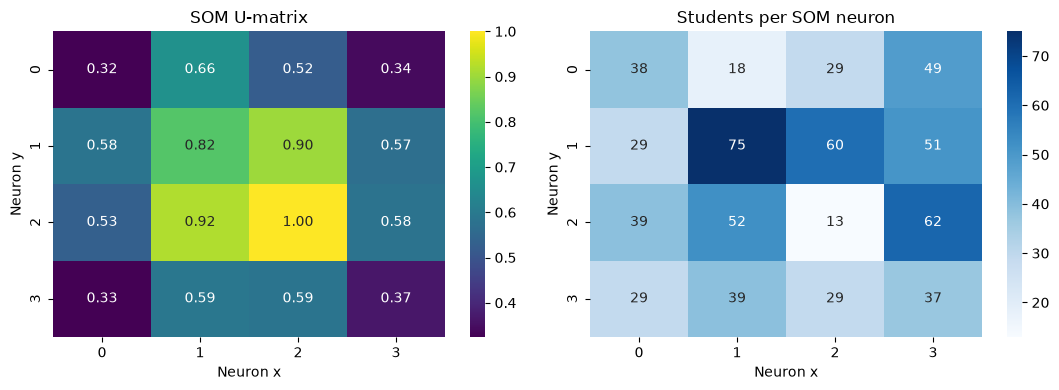

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(som_model.distance_map().T, annot=True, fmt='.2f', cmap='viridis', ax=axes[0])
axes[0].set_title('SOM U-matrix')
sns.heatmap(som_model.activation_response(som_data).T, annot=True, fmt='.0f', cmap='Blues', ax=axes[1])
axes[1].set_title('Students per SOM neuron')
for axis in axes:
    axis.set_xlabel('Neuron x')
    axis.set_ylabel('Neuron y')
plt.tight_layout()
plt.show()

### From SOM prototypes to student groups

Neuron positions represent map locations. To create candidate segmentations,
apply Ward clustering to occupied prototype vectors, then assign each student
the group of their best-matching neuron. Each occupied prototype has equal weight
in this second stage, regardless of its occupancy. This hybrid procedure extends
the course algorithms and should be checked against the direct Ward solution.

Candidate cuts 2-5 are assessed on student assignments in the encoded feature
space. The tentative cut maximizes silhouette within this set.

In [16]:
som_winners = [som_model.winner(row) for row in som_data]
occupied_neurons = sorted(set(som_winners))
occupied_weights = np.array([som_model.get_weights()[x, y] for x, y in occupied_neurons])
som_tree = linkage(occupied_weights, method='ward')
som_candidate_labels = {}
som_cluster_results = []
for k in candidate_ks:
    assert k < len(occupied_neurons)
    neuron_labels = fcluster(som_tree, t=k, criterion='maxclust') - 1
    neuron_groups = dict(zip(occupied_neurons, neuron_labels))
    labels = np.array([neuron_groups[winner] for winner in som_winners])
    assert len(np.unique(labels)) == k
    som_candidate_labels[k] = labels
    som_cluster_results.append({
        'k': k, 'Silhouette': silhouette_score(encoded_data, labels),
        'Smallest cluster': pd.Series(labels).value_counts().min()
    })
som_cluster_summary = pd.DataFrame(som_cluster_results).set_index('k')
display(som_cluster_summary.round(3))
best_som_k = int(som_cluster_summary['Silhouette'].idxmax())
som_labels = som_candidate_labels[best_som_k]

,Silhouette,Smallest cluster
k,,
2,0.064,282
3,0.056,47
4,0.051,47
5,0.031,47


## Inspect tentative assignments

Each method has its own tentative settings. Label numbers are arbitrary within
each solution. DBSCAN label -1 identifies noise. SOM_Ward labels are obtained
by grouping trained map prototypes, then assigning students through their winning
neurons. Cluster counts and original-unit profiles support interpretation.


In [17]:
assignments = pd.DataFrame({
    'KMeans': kmeans_model.labels_,
    'Ward': ward_labels[best_ward_k],
    'DBSCAN': dbscan_labels,
    'SOM_Ward': som_labels
}, index=student_data.index)
assert assignments.notna().all().all()
for method in assignments.columns:
    print(method, 'cluster sizes')
    display(assignments[method].value_counts().sort_index().to_frame('Students'))

KMeans cluster sizes


,Students
KMeans,
0,247
1,402


Ward cluster sizes


,Students
Ward,
0,246
1,403


DBSCAN cluster sizes


,Students
DBSCAN,
-1,158
0,486
1,5


SOM_Ward cluster sizes


,Students
SOM_Ward,
0,367
1,282


## Original-unit student profiles

Profile all four solutions using recorded units. DBSCAN noise appears as group -1. G1 and G2 supply additional
context. Grade patterns in the solutions using G3 are partly induced
by using G3 as an input. Mode-based category profiles are complemented by full
category percentages so minority categories remain visible.

In [18]:
profile_numeric_columns = [
    'age', 'traveltime', 'studytime', 'failures', 'absences'
] + rating_columns + ['G1', 'G2', 'G3']
for method in assignments.columns:
    profile = student_data.copy()
    profile['cluster'] = assignments[method]
    print(method, 'mean profiles in original units')
    display(profile.groupby('cluster')[profile_numeric_columns].mean().round(2))
    print(method, 'category percentages within clusters')
    for column in ['school', 'higher', 'famsup', 'schoolsup', 'internet']:
        display((pd.crosstab(profile['cluster'], profile[column], normalize='index') * 100).round(1))

KMeans mean profiles in original units


,age,traveltime,studytime,failures,absences,famrel,freetime,goout,Dalc,Walc,health,G1,G2,G3
cluster,,,,,,,,,,,,,,
0,16.96,24.53,210.02,0.32,2.74,3.86,3.22,3.17,1.52,2.25,3.44,10.30,10.45,10.69
1,16.61,14.22,259.93,0.15,4.01,3.97,3.17,3.19,1.47,2.29,3.60,12.08,12.26,12.65


KMeans category percentages within clusters


school,GP,MS
cluster,,
0,13.0,87.0
1,97.3,2.7


higher,Unknown,no,yes
cluster,,,
0,4.0,17.4,78.5
1,2.7,5.7,91.5


famsup,Unknown,no,yes
cluster,,,
0,0.8,47.4,51.8
1,1.2,33.1,65.7


... (22 outputs left out)

higher,Unknown,no,yes
cluster,,,
0,2.5,5.7,91.8
1,4.3,16.0,79.8


famsup,Unknown,no,yes
cluster,,,
0,1.1,33.2,65.7
1,1.1,45.4,53.5


schoolsup,Unknown,no,yes
cluster,,,
0,4.9,85.0,10.1
1,4.3,85.5,10.3


internet,Unknown,no,yes
cluster,,,
0,0.3,5.7,94.0
1,1.4,45.4,53.2


## Agreement and initialization sensitivity

ARI quantifies agreement between the tentative partitions on the same students.
Different feature sets can lead to different groupings. Repeated K-means seeds
provide a limited initialization check at the tentative k.

In [19]:
agreement = pd.DataFrame(index=assignments.columns, columns=assignments.columns, dtype=float)
for first in assignments.columns:
    for second in assignments.columns:
        agreement.loc[first, second] = adjusted_rand_score(assignments[first], assignments[second])
display(agreement.round(3))

seed_results = []
for seed in [0, 1, 7]:
    repeated_model = KMeans(n_clusters=best_kmeans_k, n_init=20, random_state=seed)
    repeated_model.fit(encoded_data)
    seed_results.append({
        'Seed': seed,
        'ARI vs seed 42': adjusted_rand_score(kmeans_model.labels_, repeated_model.labels_)
    })
display(pd.DataFrame(seed_results).set_index('Seed').round(3))

,KMeans,Ward,DBSCAN,SOM_Ward
KMeans,1.000,0.580,0.119,0.517
Ward,0.580,1.000,0.125,0.444
DBSCAN,0.119,0.125,1.000,0.083
SOM_Ward,0.517,0.444,0.083,1.000


,ARI vs seed 42
Seed,
0,0.969
1,0.975
7,0.982


## Sensitivity to Unknown versus mode for Yes/No responses

Missing Yes/No responses affect 140 students, approximately 21.57% of rows.
A separate copy replaces Unknown with each feature's observed source mode.
The comparison uses the same numerical scaling and tentative K-means k.

The union of dummy columns retains Unknown indicators as zero columns in the
mode scenario, preserving coordinates. This is a preprocessing sensitivity check.
Other features and the student population are held fixed.

In [20]:
mode_scenario = model_data.copy()
for column in yes_no_columns:
    observed_mode = recorded_data[column].mode().iloc[0]
    mode_scenario[column] = mode_scenario[column].replace('Unknown', observed_mode)
mode_indicators = pd.get_dummies(
    mode_scenario[categorical_columns], drop_first=False, dtype=float
).reindex(columns=categorical_indicators.columns, fill_value=0)
mode_encoded = pd.concat([scaled_numeric, mode_indicators], axis=1)
mode_model = KMeans(n_clusters=best_kmeans_k, n_init=20, random_state=SEED)
mode_model.fit(mode_encoded)

sensitivity_summary = pd.DataFrame({
    'Unknown baseline silhouette': [silhouette_score(encoded_data, kmeans_model.labels_)],
    'Mode scenario silhouette': [silhouette_score(mode_encoded, mode_model.labels_)],
    'ARI between scenarios': [adjusted_rand_score(kmeans_model.labels_, mode_model.labels_)]
})
display(sensitivity_summary.round(3))
print('Students with at least one original missing Yes/No response',
      recorded_data[yes_no_columns].isna().any(axis=1).sum())

,Unknown baseline silhouette,Mode scenario silhouette,ARI between scenarios
0,0.083,0.086,0.963


Students with at least one original missing Yes/No response 140


## Academic-feature sensitivity

Refit K-means at the same tentative k after excluding G3. Compare assignments on
identical students to examine the influence of academic performance. This extends
the lab and addresses the overlap identified in the grade correlation analysis.

In [21]:
without_grades = encoded_data.drop(columns=['G3'])
without_grade_model = KMeans(n_clusters=best_kmeans_k, n_init=20, random_state=SEED)
without_grade_model.fit(without_grades)
display(pd.DataFrame({
    'Comparison': ['Include G3 versus exclude G3'],
    'ARI': [adjusted_rand_score(kmeans_model.labels_, without_grade_model.labels_)]
}).round(3))

,Comparison,ARI
0,Include G3 versus exclude G3,0.969


## Save exploratory results

Assignments retain source row identifiers. The comparison tables support later
review of candidate settings and profiles. Exported labels remain exploratory.

In [22]:
output_directory = Path('../outputs/modelling')
output_directory.mkdir(parents=True, exist_ok=True)
assignments.to_csv(output_directory / 'exploratory_cluster_assignments.csv', index_label='student_row_id')
kmeans_summary.to_csv(output_directory / 'kmeans_candidates.csv')
ward_summary.to_csv(output_directory / 'ward_candidates.csv')
dbscan_summary.to_csv(output_directory / 'dbscan_candidates.csv', index=False)
som_grid_summary.to_csv(output_directory / 'som_grid_candidates.csv', index=False)
som_cluster_summary.to_csv(output_directory / 'som_cluster_candidates.csv')
sensitivity_summary.to_csv(output_directory / 'yes_no_sensitivity.csv', index=False)
print('Exploratory results saved to', output_directory.as_posix())

Exploratory results saved to ../outputs/modelling


## Interpretation of this executed baseline

K-means selects two groups within the 2-5 range, with silhouette approximately
0.083. Ward also selects two groups, with silhouette approximately 0.064. These
low values indicate overlapping profiles under the current representation.
They provide limited support for treating the groups as clearly separated types.

The tentative DBSCAN candidate uses eps approximately 2.604 and min_samples = 5.
It assigns 491 students and marks 158 (24.35%) as noise. Its silhouette of about
0.109 covers assigned students only. The assigned groups contain 486 and 5 students, so the smaller group needs
careful review before interpreting this as a useful segmentation.

All 16 neurons of the provisional 4x4 SOM are occupied. Quantization error is
approximately 2.456 and topographic error is 0.550. Topology preservation is weak
under these settings. The two-group Ward cut of occupied prototypes gives student
silhouette approximately 0.064. Map size, neighborhood radius, learning schedule,
and training duration require further examination before adopting SOM profiles.

Replacing Unknown with observed modes in the Yes/No fields gives K-means ARI
approximately 0.963 versus the Unknown baseline. The partitions are similar in this
specific experiment, although that result does not establish individual imputation
accuracy or stability for every model and preprocessing choice.

RFM applicability is documented against the source schema. Calculating RFM scores
requires dated event records and a defined value measure, which this CSV lacks.
The current numerical clustering results support further feature and weighting
experiments before a final educational segmentation is selected.


## Review before selecting a final solution

Use candidate tables, dendrograms, SOM diagnostics, group sizes, original-unit
profiles and sensitivity comparisons together. Explain whether differences
represent useful educational support profiles. DBSCAN noise requires separate
inspection, while SOM neuron occupancy and prototype groups have distinct roles.

The selected settings remain provisional within the explored grids. Review
feature weighting, preprocessing choices, small groups, initialization, and
stability before adopting a final model or naming educational profiles.
RFM requires suitable dated interaction data and a defensible value measure.
